In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import math
import os

warnings.filterwarnings('ignore')
os.makedirs('models', exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             balanced_accuracy_score,
                             f1_score,
                             matthews_corrcoef)

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('OK - Imports done')

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
OK - Imports done


In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# ── Features avec noms uniques ───────────────────────────
with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(f'{feat}_{seen[feat]}')
    else:
        seen[feat] = 0
        features_unique.append(feat)

print(f'Features uniques : {len(features_unique)}')

# ── Charger X ────────────────────────────────────────────
X_train_raw = pd.read_csv(f'{BASE}/train/X_train.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)
X_test_raw  = pd.read_csv(f'{BASE}/test/X_test.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)

# ── Charger y ────────────────────────────────────────────
y_train_raw = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw  = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]

print(f'X_train_raw : {X_train_raw.shape}')
print(f'X_test_raw  : {X_test_raw.shape}')
print('✅ Données chargées')

Mounted at /content/drive
Features uniques : 561
X_train_raw : (7352, 561)
X_test_raw  : (2947, 561)
✅ Données chargées


In [3]:
CLASS_NAMES = ['LAYING','SITTING','STANDING','WALKING',
               'WALKING_DOWNSTAIRS','WALKING_UPSTAIRS']

# ── Encodage labels ──────────────────────────────────────
le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

# ── Normalisation ────────────────────────────────────────
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

# ── Reshape 64×9 = 576 (pad de 15 zeros) ────────────────
# 576 = 64 timesteps × 9 canaux (accéléro x,y,z + gyro x,y,z + total x,y,z)
target     = 576
pad        = target - X_train.shape[1]   # 576 - 561 = 15
X_train_p  = np.pad(X_train, ((0,0),(0,pad)), mode='constant')
X_test_p   = np.pad(X_test,  ((0,0),(0,pad)), mode='constant')

X_train_3d = X_train_p.reshape(X_train_p.shape[0], 64, 9)
X_test_3d  = X_test_p.reshape(X_test_p.shape[0],   64, 9)

print(f'Padding        : {X_train.shape[1]} → {target} (+{pad} zeros)')
print(f'X_train_3d     : {X_train_3d.shape}  (samples, timesteps, canaux)')
print(f'X_test_3d      : {X_test_3d.shape}')
print(f'NUM_CLASSES    : {NUM_CLASSES}')
print(f'Classes        : {CLASS_NAMES}')
print('✅ Préprocessing OK')

Padding        : 561 → 576 (+15 zeros)
X_train_3d     : (7352, 64, 9)  (samples, timesteps, canaux)
X_test_3d      : (2947, 64, 9)
NUM_CLASSES    : 6
Classes        : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
✅ Préprocessing OK


In [4]:
def mixup_data(X, y, alpha=0.2, seed=42):
    """
    Mixup : mélange linéaire de deux samples
    Réduit la sur-confiance et améliore la généralisation
    """
    np.random.seed(seed)
    lam   = np.random.beta(alpha, alpha, size=len(X))
    lam   = np.maximum(lam, 1 - lam)   # lam > 0.5 toujours
    idx   = np.random.permutation(len(X))

    X_mix = np.array([lam[i]*X[i] + (1-lam[i])*X[idx[i]]
                      for i in range(len(X))])
    y_mix = np.array([lam[i]*y[i] + (1-lam[i])*y[idx[i]]
                      for i in range(len(y))])
    return X_mix, y_mix

def jitter_data(X, sigma=0.05, seed=43):
    """Ajout de bruit gaussien"""
    np.random.seed(seed)
    return X + np.random.normal(0, sigma, X.shape)

def scale_data(X, min_s=0.8, max_s=1.2, seed=44):
    """Changement d'amplitude aléatoire"""
    np.random.seed(seed)
    scales = np.random.uniform(min_s, max_s, (len(X), 1, 1))
    return X * scales

# ── Appliquer toutes les augmentations ───────────────────
X_mix,    y_mix    = mixup_data(X_train_3d, y_train_ohe, alpha=0.2)
X_jitter           = jitter_data(X_train_3d)
X_scaled           = scale_data(X_train_3d)

X_combined = np.concatenate([X_train_3d, X_mix, X_jitter, X_scaled], axis=0)
y_combined = np.concatenate([y_train_ohe, y_mix, y_train_ohe, y_train_ohe], axis=0)

# Shuffle
idx_shuffle = np.random.permutation(len(X_combined))
X_combined  = X_combined[idx_shuffle]
y_combined  = y_combined[idx_shuffle]

print(f'Train original  : {X_train_3d.shape}')
print(f'Train augmenté  : {X_combined.shape}  (×4 samples)')
print('✅ Augmentation OK')

Train original  : (7352, 64, 9)
Train augmenté  : (29408, 64, 9)  (×4 samples)
✅ Augmentation OK


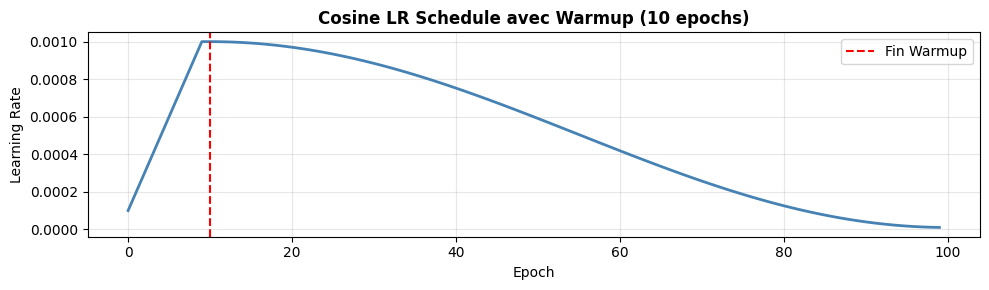

✅ Callbacks prêts


In [5]:
def cosine_warmup_lr(epoch, lr, warmup=10, total=100,
                     min_lr=1e-5, max_lr=1e-3):
    """Cosine Annealing avec Warmup linéaire"""
    if epoch < warmup:
        return max_lr * (epoch + 1) / warmup
    progress = (epoch - warmup) / (total - warmup)
    return min_lr + 0.5*(max_lr - min_lr)*(1 + math.cos(math.pi * progress))

def get_callbacks_v2(model_name, patience=15, total_epochs=100):
    return [
        EarlyStopping(
            monitor='val_accuracy',
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_warmup_lr(
                epoch, lr, total=total_epochs
            ), verbose=0
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=f'models/{model_name}_best.keras',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=0
        )
    ]

# Visualiser le LR schedule
lrs = [cosine_warmup_lr(e, 1e-3) for e in range(100)]
plt.figure(figsize=(10, 3))
plt.plot(lrs, color='steelblue', linewidth=2)
plt.title('Cosine LR Schedule avec Warmup (10 epochs)', fontweight='bold')
plt.xlabel('Epoch'); plt.ylabel('Learning Rate')
plt.axvline(x=10, color='red', linestyle='--', label='Fin Warmup')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('models/lr_schedule.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Callbacks prêts')

In [6]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{model_name} — Courbes entraînement',
                 fontsize=13, fontweight='bold')
    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'models/{model_name}_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

def evaluate_model(model, X_input, y_int, model_name):
    y_pred   = np.argmax(model.predict(X_input, verbose=0), axis=1)
    acc      = accuracy_score(y_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_int, y_pred)
    macro_f1 = f1_score(y_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_int, y_pred)
    print(f'\n{"═"*55}')
    print(f'  📊 {model_name}')
    print(f'{"═"*55}')
    print(f'  Accuracy          : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1          : {macro_f1:.4f}')
    print(f'  MCC               : {mcc:.4f}')
    print(f'{"═"*55}')
    print(classification_report(y_int, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{model_name} — Confusion Matrix',
              fontsize=13, fontweight='bold')
    plt.ylabel('Réel'); plt.xlabel('Prédit')
    plt.xticks(rotation=30); plt.tight_layout()
    plt.savefig(f'models/{model_name}_confusion.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    return {
        'Modèle'           : model_name,
        'Accuracy'         : round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Macro_F1'         : round(macro_f1, 4),
        'MCC'              : round(mcc, 4)
    }

results = []
print('✅ Fonctions prêtes')

✅ Fonctions prêtes


In [7]:
def build_cnn_lstm_v2(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    # ── Bloc CNN 1 ───────────────────────────────────────
    x = layers.Conv1D(64, kernel_size=3, padding='same',
                      activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, kernel_size=3, padding='same',
                      activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.2)(x)

    # ── Bloc CNN 2 ───────────────────────────────────────
    x = layers.Conv1D(128, kernel_size=3, padding='same',
                      activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(128, kernel_size=3, padding='same',
                      activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.2)(x)

    # ── Bloc CNN 3 ───────────────────────────────────────
    x = layers.Conv1D(256, kernel_size=3, padding='same',
                      activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    # ── BiLSTM 1 ─────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True, dropout=0.2)
    )(x)
    x = layers.BatchNormalization()(x)

    # ── BiLSTM 2 ─────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(64, return_sequences=True, dropout=0.2)
    )(x)
    x = layers.BatchNormalization()(x)

    # ── Multi-Head Attention ─────────────────────────────
    attn = layers.MultiHeadAttention(
        num_heads=4, key_dim=16, name='attention'
    )(x, x)
    x = layers.Add()([x, attn])          # Residual
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)

    # ── Classifieur ──────────────────────────────────────
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64,  activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs, name='CNN_LSTM_V2')
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )
    return model

cnn_lstm_v2 = build_cnn_lstm_v2(X_train_3d.shape[1:], NUM_CLASSES)
cnn_lstm_v2.summary()
print(f'\nTotal paramètres : {cnn_lstm_v2.count_params():,}')

Model: "CNN_LSTM_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 9)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 64, 64)    │      1,792 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 64, 64)    │     12,352 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64)    │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 32, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32, 64)    │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 32, 128)   │     24,704 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 128)   │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 32, 128)   │     49,280 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 128)   │        512 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 16, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16, 128)   │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 16, 256)   │     98,560 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 256)   │      1,024 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16, 256)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 16, 256)   │    394,240 │ dropout_2[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 256)   │      1,024 │ bidirectional[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 16, 128)   │    164,352 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 807,878 (3.08 MB)

 Trainable params: 805,830 (3.07 MB)

 Non-trainable params: 2,048 (8.00 KB)


Total paramètres : 807,878


Epoch 1/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 25s 42ms/step - accuracy: 0.4727 - loss: 1.3573 - val_accuracy: 0.3804 - val_loss: 1.4446 - learning_rate: 1.0000e-04
Epoch 2/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.7572 - loss: 0.9260 - val_accuracy: 0.8307 - val_loss: 0.7501 - learning_rate: 2.0000e-04
Epoch 3/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.8948 - loss: 0.7143 - val_accuracy: 0.8996 - val_loss: 0.6303 - learning_rate: 3.0000e-04
Epoch 4/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.9382 - loss: 0.6321 - val_accuracy: 0.9067 - val_loss: 0.6199 - learning_rate: 4.0000e-04
Epoch 5/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.9596 - loss: 0.5867 - val_accuracy: 0.9277 - val_loss: 0.5857 - learning_rate: 5.0000e-04
Epoch 6/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.9677 - loss: 0.5643 - val_accuracy: 0.8860 - val_loss: 0.7141 - learning_rate: 6.0000e-04
Epoch 7/100
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/s

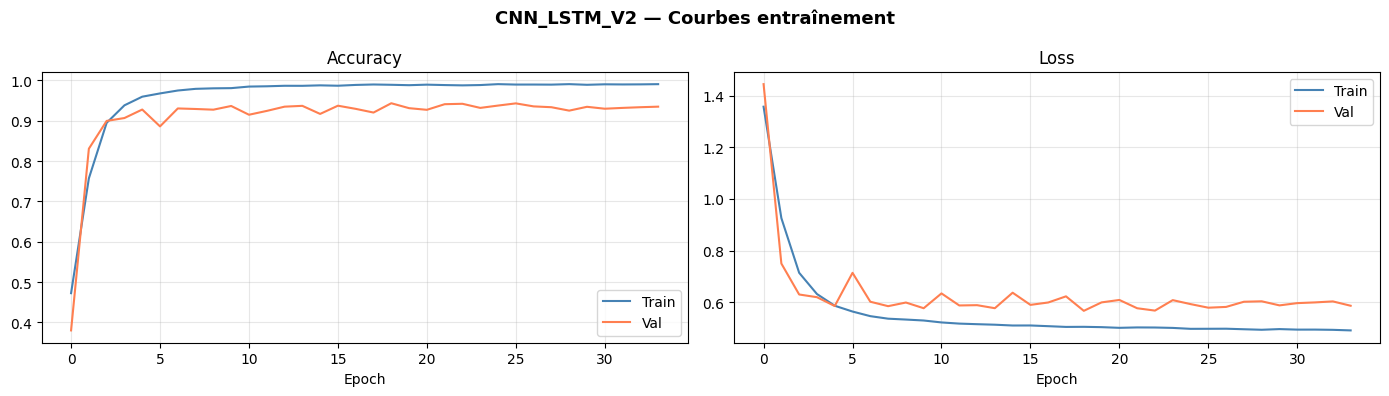


═══════════════════════════════════════════════════════
  📊 CNN-LSTM V2
═══════════════════════════════════════════════════════
  Accuracy          : 0.9433 (94.33%)
  Balanced Accuracy : 0.9430
  Macro F1          : 0.9433
  MCC               : 0.9321
═══════════════════════════════════════════════════════
                    precision    recall  f1-score   support

            LAYING       0.92      0.98      0.95       496
           SITTING       0.96      0.92      0.94       471
          STANDING       0.98      0.94      0.96       420
           WALKING       0.89      0.92      0.90       491
WALKING_DOWNSTAIRS       0.93      0.89      0.91       532
  WALKING_UPSTAIRS       1.00      1.00      1.00       537

          accuracy                           0.94      2947
         macro avg       0.94      0.94      0.94      2947
      weighted avg       0.94      0.94      0.94      2947



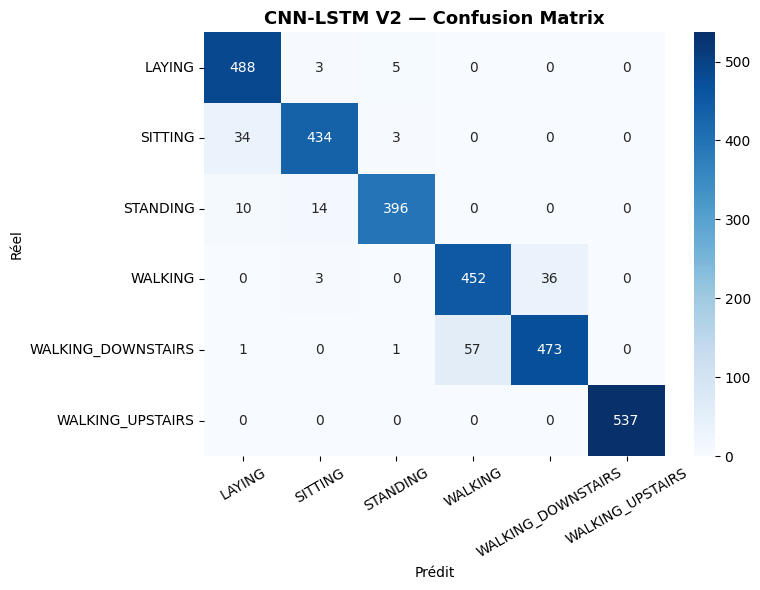

In [8]:
# ── Entraînement ─────────────────────────────────────────
history_v2 = cnn_lstm_v2.fit(
    X_combined, y_combined,        # ← données augmentées ×4
    epochs=100,
    batch_size=128,
    validation_data=(X_test_3d, y_test_ohe),
    callbacks=get_callbacks_v2('CNN_LSTM_V2'),
    verbose=1
)

# ── Epochs exact ─────────────────────────────────────────
best_epoch   = np.argmax(history_v2.history['val_accuracy']) + 1
total_epochs = len(history_v2.history['val_accuracy'])
best_val_acc = max(history_v2.history['val_accuracy'])

print(f'\n{"═"*45}')
print(f'  ⏱️  Epochs total      : {total_epochs}')
print(f'  🏆  Meilleure epoch   : {best_epoch}')
print(f'  📈  Meilleure val_acc : {best_val_acc:.4f}')
print(f'{"═"*45}')
# ── Visualisation & Évaluation ───────────────────────────
plot_history(history_v2, 'CNN_LSTM_V2')
res_v2 = evaluate_model(cnn_lstm_v2, X_test_3d, y_test, 'CNN-LSTM V2')
results.append(res_v2)